# Insurance Claims Analytics — Python analysis layer

This notebook pulls results from the SQL layer (`queries/analysis_queries.sql`) into pandas,
visualises the key fraud patterns, and runs a simple z-score anomaly detector that is
**checked against the real `fraud_reported` label** — something most student projects can't do
because they lack ground truth.

**Findings are written up in `ANALYSIS.md` (F1–F8).** This notebook is the evidence behind them.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from db.connection import get_engine
from queries.run_queries import split_statements  # reuse the .sql parser

CHARTS_DIR = PROJECT_ROOT / "charts"
CHARTS_DIR.mkdir(exist_ok=True)
engine = get_engine()

# ---- shared chart styling (CVD-safe palette, recessive chrome) -------------
INK      = "#0b0b0b"
INK_SOFT = "#52514e"
MUTED    = "#898781"
GRID     = "#e1e0d9"
C_LEGIT  = "#2a78d6"   # categorical slot 1 (blue)
C_FRAUD  = "#d03b3b"   # status: critical (red)  -> fraud
C_SINGLE = "#2a78d6"

plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_SOFT,
    "text.color": INK, "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
})

def run_sql(query_number: int) -> pd.DataFrame:
    stmts = split_statements((PROJECT_ROOT / "queries" / "analysis_queries.sql").read_text())
    title, code_ = stmts[query_number - 1]
    print(title)
    return pd.read_sql(code_, engine)

def bar_labels(ax, fmt="{:.0f}", pad=3, vertical=True):
    for p in ax.patches:
        if vertical:
            v = p.get_height()
            ax.annotate(fmt.format(v), (p.get_x() + p.get_width()/2, v),
                        ha="center", va="bottom", xytext=(0, pad),
                        textcoords="offset points", fontsize=9, color=INK_SOFT)
        else:
            v = p.get_width()
            ax.annotate(fmt.format(v), (v, p.get_y() + p.get_height()/2),
                        ha="left", va="center", xytext=(pad, 0),
                        textcoords="offset points", fontsize=9, color=INK_SOFT)

FRAUD_BASE = pd.read_sql("SELECT AVG(fraud_reported='Y')*100 r FROM claims", engine).r.iloc[0]
print(f"Portfolio fraud rate: {FRAUD_BASE:.1f}%")

Portfolio fraud rate: 24.7%


## 1. Fraud rate by incident severity × type (Q1)

Where does fraud actually live?

Q1. Fraud rate by incident severity x incident type, ranked.


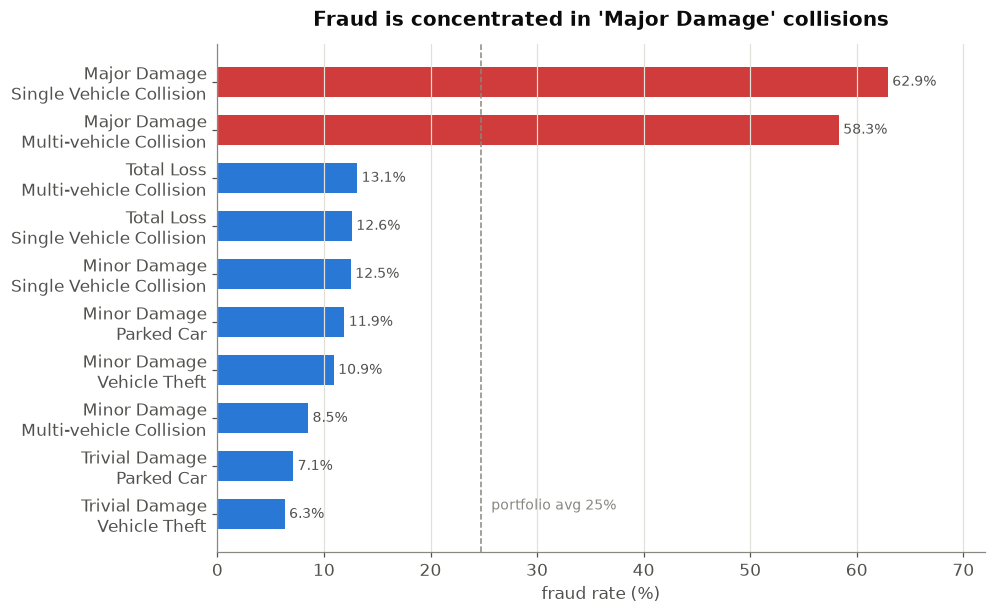

In [2]:
q1 = run_sql(1)
q1["label"] = q1.incident_severity + "\n" + q1.incident_type
q1 = q1.sort_values("fraud_rate_pct")

fig, ax = plt.subplots(figsize=(9, 6))
colors = np.where(q1.fraud_rate_pct >= 40, C_FRAUD, C_SINGLE)
ax.barh(q1.label, q1.fraud_rate_pct, color=colors, height=0.62)
ax.axvline(FRAUD_BASE, color=MUTED, ls="--", lw=1)
ax.text(FRAUD_BASE + 1, 0.1, f"portfolio avg {FRAUD_BASE:.0f}%", color=MUTED, fontsize=9)
bar_labels(ax, "{:.1f}%", vertical=False)
ax.set_xlabel("fraud rate (%)"); ax.set_xlim(0, 72)
ax.set_title("Fraud is concentrated in 'Major Damage' collisions")
ax.grid(axis="y", visible=False)
plt.savefig(CHARTS_DIR / "01_fraud_by_severity_type.png"); plt.show()

## 2. Fraud rate by state (Q6)

Is geography a useful lever? (Spoiler: barely.)

Q6. State-level fraud & cost comparison, ranked.


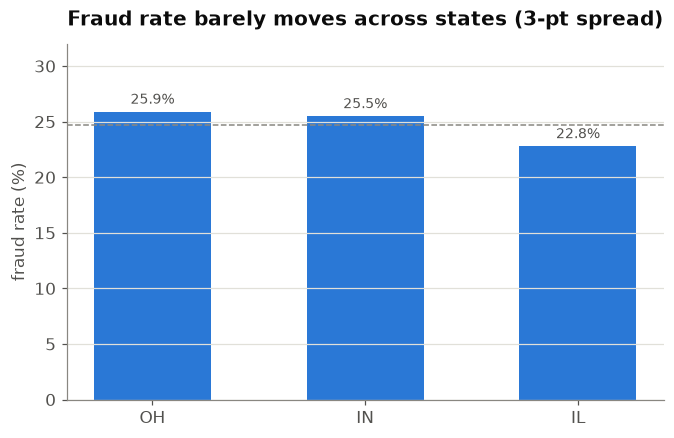

In [3]:
q6 = run_sql(6)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(q6.policy_state, q6.fraud_rate_pct, color=C_SINGLE, width=0.55)
ax.axhline(FRAUD_BASE, color=MUTED, ls="--", lw=1)
bar_labels(ax, "{:.1f}%")
ax.set_ylabel("fraud rate (%)"); ax.set_ylim(0, 32)
ax.set_title("Fraud rate barely moves across states (3-pt spread)")
ax.grid(axis="x", visible=False)
plt.savefig(CHARTS_DIR / "02_fraud_by_state.png"); plt.show()

## 3. Claim amount: fraud vs legitimate, by severity (Q4)

Do fraudsters claim *more* money? The distributions say no.

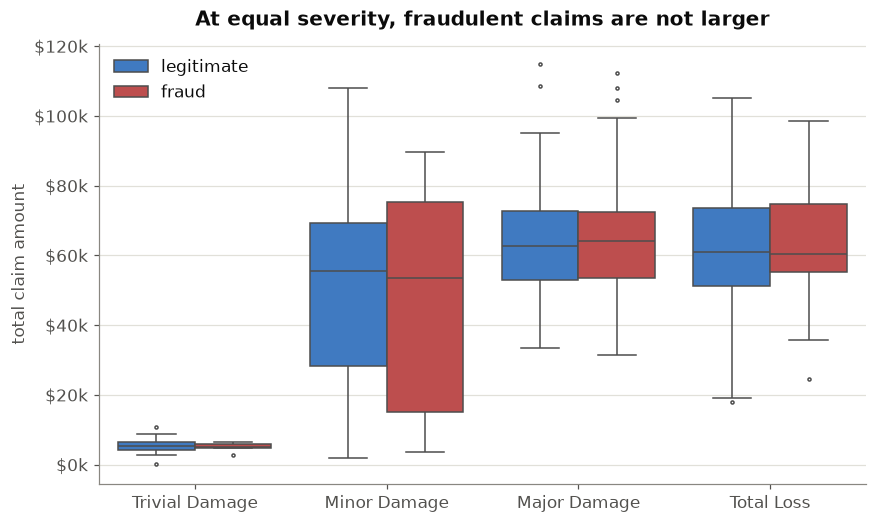

Q4. Average claim amount by severity: fraud vs non-fraud, side by side.


,incident_severity,claims,avg_amount_fraud,avg_amount_legit,fraud_premium_abs
0,Total Loss,280,64041.0,61792.0,2249.0
1,Major Damage,276,64116.0,63993.0,123.0
2,Minor Damage,354,48726.0,48633.0,93.0
3,Trivial Damage,90,5038.0,5320.0,-282.0


In [4]:
claims = pd.read_sql('''
    SELECT i.incident_severity, c.total_claim_amount,
           CASE WHEN c.fraud_reported='Y' THEN 'fraud' ELSE 'legitimate' END AS kind
    FROM claims c JOIN incidents i ON i.incident_id = c.incident_id
''', engine)
order = ["Trivial Damage", "Minor Damage", "Major Damage", "Total Loss"]

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.boxplot(data=claims, x="incident_severity", y="total_claim_amount", hue="kind",
            order=order, hue_order=["legitimate", "fraud"],
            palette={"legitimate": C_LEGIT, "fraud": C_FRAUD}, fliersize=2, ax=ax)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.set_xlabel(""); ax.set_ylabel("total claim amount")
ax.set_title("At equal severity, fraudulent claims are not larger")
ax.legend(title="", frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
plt.savefig(CHARTS_DIR / "03_claim_amount_fraud_vs_legit.png"); plt.show()

q4 = run_sql(4); q4

## 4. Fraud rate by age bracket (Q2)

Aggregated across education levels.

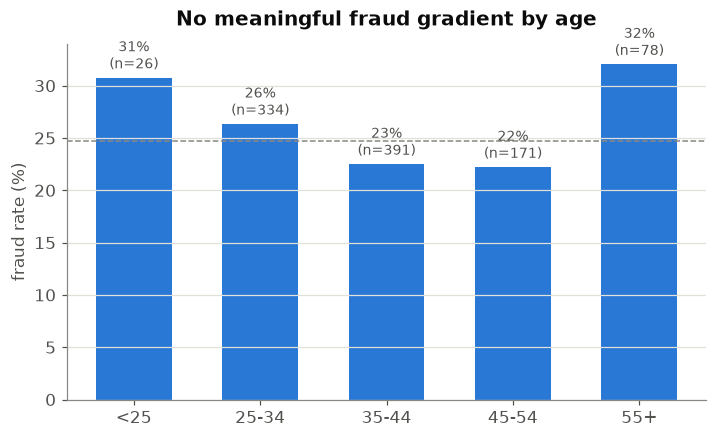

In [5]:
age = pd.read_sql('''
    SELECT CASE WHEN p.age<25 THEN '<25' WHEN p.age<35 THEN '25-34'
                WHEN p.age<45 THEN '35-44' WHEN p.age<55 THEN '45-54' ELSE '55+' END AS age_bracket,
           AVG(c.fraud_reported='Y')*100 AS fraud_rate_pct, COUNT(*) AS claims
    FROM policies p JOIN claims c ON c.policy_number=p.policy_number
    GROUP BY age_bracket ORDER BY MIN(p.age)
''', engine)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(age.age_bracket, age.fraud_rate_pct, color=C_SINGLE, width=0.6)
ax.axhline(FRAUD_BASE, color=MUTED, ls="--", lw=1)
for x, r, n in zip(age.age_bracket, age.fraud_rate_pct, age.claims):
    ax.annotate(f"{r:.0f}%\n(n={n})", (x, r), ha="center", va="bottom",
                xytext=(0, 3), textcoords="offset points", fontsize=9, color=INK_SOFT)
ax.set_ylabel("fraud rate (%)"); ax.set_ylim(0, 34)
ax.set_title("No meaningful fraud gradient by age")
ax.grid(axis="x", visible=False)
plt.savefig(CHARTS_DIR / "04_fraud_by_age.png"); plt.show()

## 5. Fraud rate by vehicle make (Q9)

The one 'soft' feature with a real gradient.

Q9. Vehicle-make fraud pattern (makes with a usable sample only).


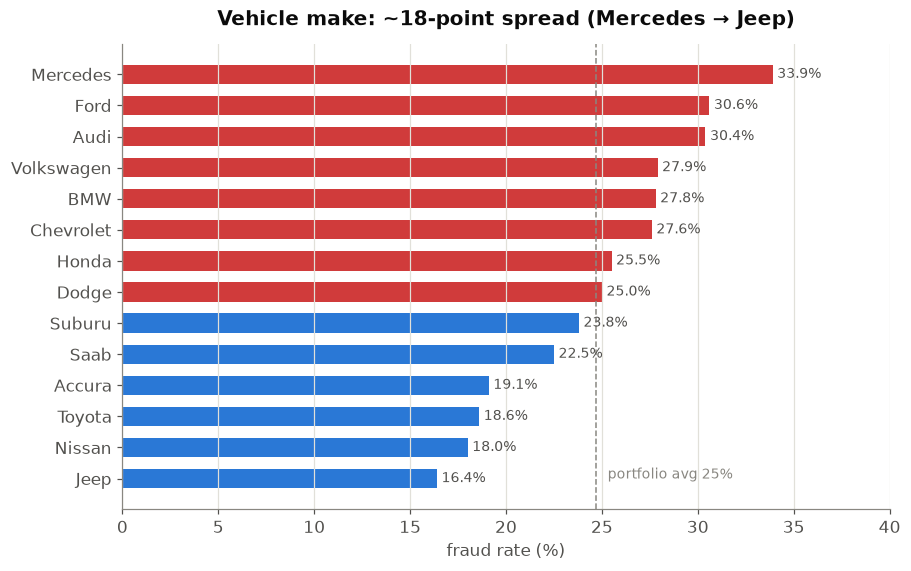

In [6]:
q9 = run_sql(9).sort_values("fraud_rate_pct")
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = np.where(q9.fraud_rate_pct >= FRAUD_BASE, C_FRAUD, C_SINGLE)
ax.barh(q9.auto_make, q9.fraud_rate_pct, color=colors, height=0.62)
ax.axvline(FRAUD_BASE, color=MUTED, ls="--", lw=1)
ax.text(FRAUD_BASE + 0.6, 0.0, f"portfolio avg {FRAUD_BASE:.0f}%", color=MUTED, fontsize=9)
bar_labels(ax, "{:.1f}%", vertical=False)
ax.set_xlabel("fraud rate (%)"); ax.set_xlim(0, 40)
ax.set_title("Vehicle make: ~18-point spread (Mercedes → Jeep)")
ax.grid(axis="y", visible=False)
plt.savefig(CHARTS_DIR / "05_fraud_by_make.png"); plt.show()

## 6. Cumulative claim cost over the period (Q10)

Running total, Jan–Mar 2015.

Q10. Running cumulative claim cost over time.


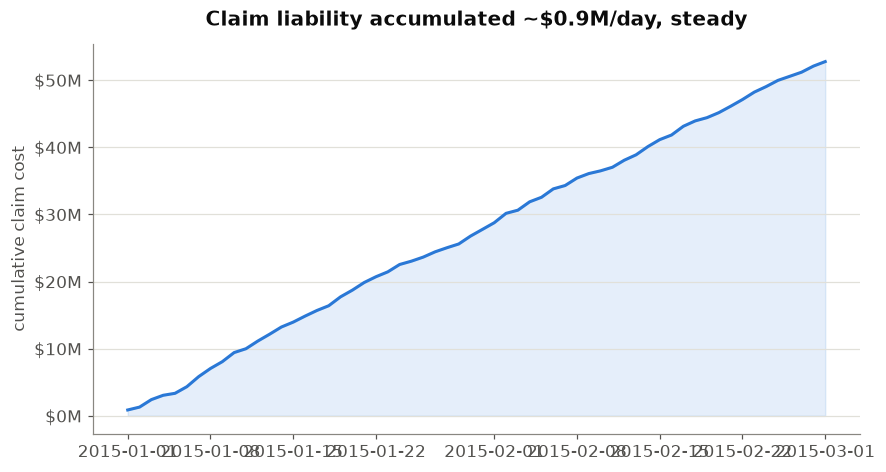

In [7]:
q10 = run_sql(10)
q10["incident_date"] = pd.to_datetime(q10.incident_date)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(q10.incident_date, q10.running_total / 1e6, color=C_SINGLE, lw=2)
ax.fill_between(q10.incident_date, q10.running_total / 1e6, color=C_SINGLE, alpha=0.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:.0f}M"))
ax.set_ylabel("cumulative claim cost"); ax.set_xlabel("")
ax.set_title("Claim liability accumulated ~$0.9M/day, steady")
ax.grid(axis="x", visible=False)
plt.savefig(CHARTS_DIR / "06_cumulative_claim_cost.png"); plt.show()

## 7. Z-score anomaly detection, checked against ground truth

A lightweight, unsupervised flag: for each `incident_severity` group, compute the z-score of
`total_claim_amount` and flag `|z| > 3`. Then — because this dataset has a real `fraud_reported`
label — we can actually measure how good that flag is.

In [8]:
df = pd.read_sql('''
    SELECT c.claim_id, i.incident_severity, c.total_claim_amount, c.fraud_reported
    FROM claims c JOIN incidents i ON i.incident_id = c.incident_id
''', engine)

df["z"] = df.groupby("incident_severity").total_claim_amount.transform(
    lambda s: (s - s.mean()) / s.std(ddof=0))
df["anomaly"] = df.z.abs() > 3
df["is_fraud"] = df.fraud_reported.eq("Y")

n_anom = int(df.anomaly.sum())
tp = int((df.anomaly & df.is_fraud).sum())
print(f"Flagged {n_anom} claims as amount-anomalies (|z| > 3).")
if n_anom:
    print(f"  precision = {tp}/{n_anom} = {tp/n_anom:.0%}  (of flagged claims that are truly fraud)")
print(f"  recall    = {tp}/{int(df.is_fraud.sum())} = {tp/df.is_fraud.sum():.1%}  (of all fraud caught by this flag)")

conf = pd.crosstab(df.anomaly, df.is_fraud, rownames=["|z|>3"], colnames=["fraud"])
print("\nConfusion matrix:"); print(conf)

Flagged 4 claims as amount-anomalies (|z| > 3).
  precision = 1/4 = 25%  (of flagged claims that are truly fraud)
  recall    = 1/247 = 0.4%  (of all fraud caught by this flag)

Confusion matrix:
fraud  False  True 
|z|>3              
False    750    246
True       3      1


In [9]:
# Contrast: a *severity*-based rule ("investigate all Major Damage") on the same data
rule = df.incident_severity.eq("Major Damage")
tp_r = int((rule & df.is_fraud).sum())
print("Baseline rule — flag every 'Major Damage' claim:")
print(f"  flags {int(rule.sum())} claims | precision {tp_r/rule.sum():.0%} | recall {tp_r/df.is_fraud.sum():.0%}")
print()
print("Takeaway: the z-score amount-anomaly flag is near useless for fraud here")
print("(F3 — fraud isn't about claim size). A one-line severity rule dominates it.")

Baseline rule — flag every 'Major Damage' claim:
  flags 276 claims | precision 61% | recall 68%

Takeaway: the z-score amount-anomaly flag is near useless for fraud here
(F3 — fraud isn't about claim size). A one-line severity rule dominates it.


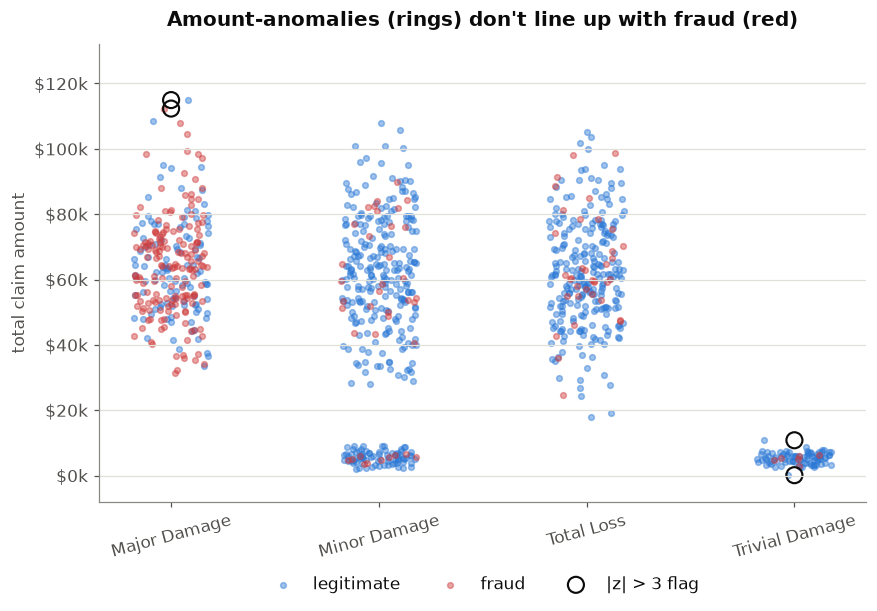

In [10]:
rng = np.random.default_rng(0)
cats = df.incident_severity.astype("category")
fig, ax = plt.subplots(figsize=(9, 5.4))
for kind, sub in df.groupby(df.is_fraud):
    ax.scatter(cats.cat.codes[sub.index] + rng.uniform(-0.18, 0.18, len(sub)),
               sub.total_claim_amount, s=14, alpha=0.45,
               color=C_FRAUD if kind else C_LEGIT,
               label="fraud" if kind else "legitimate")
anom = df[df.anomaly]
ax.scatter(cats.cat.codes[anom.index], anom.total_claim_amount, s=110,
           facecolors="none", edgecolors=INK, linewidths=1.4, label="|z| > 3 flag")
ax.set_xticks(range(cats.cat.categories.size))
ax.set_xticklabels(cats.cat.categories, rotation=15)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.set_ylabel("total claim amount"); ax.set_ylim(-8000, 132000)
ax.set_title("Amount-anomalies (rings) don't line up with fraud (red)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
ax.grid(axis="x", visible=False)
plt.savefig(CHARTS_DIR / "07_zscore_anomaly_vs_fraud.png"); plt.show()

## Summary

| Question | Answer |
|---|---|
| Where is fraud? | **`incident_severity` = 'Major Damage'** — 60% fraud vs ~11% elsewhere (F2) |
| Do fraudsters claim more $? | **No** — same amount at equal severity (F3) |
| Is claim size a good filter? | **No** — flat fraud rate across top 8 cost deciles (F4) |
| Vehicle make? | Real ~18-pt gradient, likely confounded — model feature only (F5) |
| Age / state / season / policy-age? | **No usable signal** in this book (F6) |
| Does a z-score $ anomaly flag find fraud? | **No** (~base-rate precision) — confirms F3 |

See `ANALYSIS.md` for the full write-up with recommended actions and caveats.